# 🚀 MLOps End-to-End com MLflow 3.3.1 — Previsão de Churn Out-of-Time

**Autor:** Dr. Silvio da Rosa Paula • Portfólio de Machine Learning & MLOps  
**Plataforma de Governança:** **MLflow `3.3.1`** (SQLite Tracking Store + Model Registry + Aliases `@baseline` / `@challenger` / `@champion`)  
**Dataset:** **`4,055` registros comportamentais (`1,506` clientes únicos, `92` features em 4 janelas)** de **Abr/2024 a Nov/2024** (`data/abt.csv`)

---

## 🎯 Contexto de Negócio & Arquitetura MLOps de Produção

Treinar um modelo em notebook é apenas o início do ciclo de vida de Machine Learning. Em produção, a perda silenciosa de desempenho decorre de quatro falhas clássicas — todas auditadas e resolvidas neste pipeline:

1. **Vazamento Temporal e de Entidade (*Leakage*):** substituímos o `train_test_split` aleatório do projeto legado por um **Split Cronológico Out-of-Time (OOT)** estrito (**Treino `Abr–Jul/2024`**, **Validação `Ago–Set/2024`** e **Teste Cego OOT `Out–Nov/2024`**), reduzindo sobreposição indevida de safras futuras (`479` → `260` clientes entre janelas).
2. **Zero *Training-Serving Skew*:** encapsulamos o transformador customizado `ChurnFeatureEngineer` (indicadores de inatividade `d7/d14`, razões comportamentais e medianas congeladas no treino) dentro do `Pipeline` salvo no **MLflow Model Registry** (`serve_roundtrip_max_diff = 1.11e-16`).
3. **Governança Automatizada no MLflow Model Registry (`churn-predictor`):** rastreamos **9 pipelines** com *Signature* (`infer_signature`), *Input Example*, IC 95% Bootstrap e Brier Score, promovendo `@champion` via **Quality Gate automatizado** (`APROVADO`).
4. **Monitoramento de Drift (PSI) & Valor Financeiro (ROI):** medimos o **Population Stability Index (PSI)** entre Treino e Safras OOT (`9` features com `PSI > 0,25`, lideradas pelo envelhecimento natural de `tenure`) e otimizamos o *threshold* de campanha de retenção maximizando o **Lucro Líquido** (**`R\$ 18,180.00`** no OOT, **`+R\$ 4,815.00`** sobre abordar toda a base).

## 1. Auditoria da ABT, Coortes Mensais, Missingness Estrutural & Vazamento

2026/11/26 15:51:19 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/26 15:51:19 INFO mlflow.store.db.utils: Updating database tables


INFO  [alembic.runtime.migration] Context impl SQLiteImpl.


INFO  [alembic.runtime.migration] Will assume non-transactional DDL.


INFO  [alembic.runtime.migration] Context impl SQLiteImpl.


INFO  [alembic.runtime.migration] Will assume non-transactional DDL.


MLflow 3.3.1 ativo | Experimento: 'churn_mlops_oot_benchmark' (ID=1)
Tracking URI: sqlite:///mlflow_store/mlflow.db | Total runs rastreadas: 9


,Safra (YYYY-MM),Registros,Clientes Únicos,Taxa Churn,% Inativo d7,% Inativo d14
0,2024-04,1104,797,0.4139,0.3859,0.2255
1,2024-05,527,514,0.3871,0.3871,0.2543
2,2024-06,522,518,0.4291,0.3640,0.2165
3,2024-07,539,503,0.4583,0.3822,0.2301
4,2024-08,420,399,0.3857,0.3619,0.2333
5,2024-09,400,400,0.4675,0.4725,0.3200
6,2024-10,385,365,0.5299,0.4753,0.2675
7,2024-11,158,158,0.4810,0.5063,0.3987


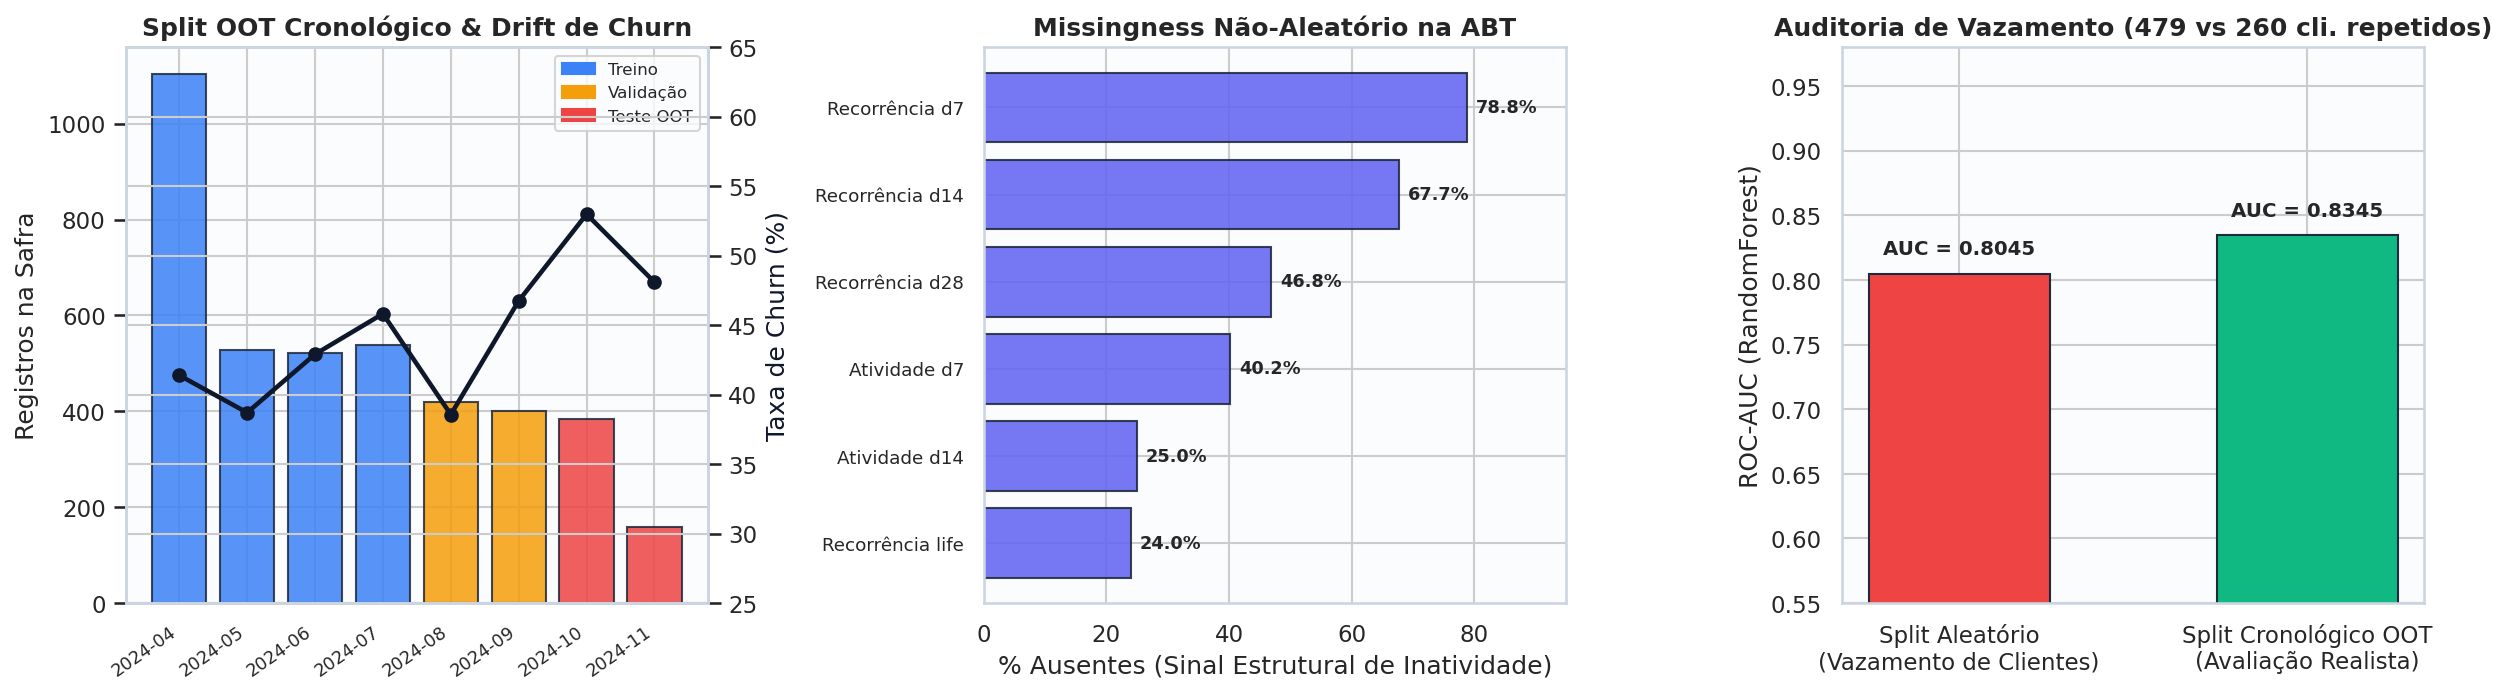

In [1]:
import json, sys, warnings
from pathlib import Path

warnings.filterwarnings("ignore")
ROOT = Path(".").resolve()
sys.path.insert(0, str(ROOT / "src"))

import mlflow
from mlflow.tracking import MlflowClient
import pandas as pd
from IPython.display import Image, display

from churn_mlops import DEFAULT_EXPERIMENT, DEFAULT_MODEL_NAME, get_tracking_uri

FIG_DIR = ROOT / "outputs" / "figures"
metrics = json.loads((ROOT / "outputs" / "metrics_summary.json").read_text(encoding="utf-8"))

# Conecta ao MLflow Tracking Store SQLite local real!
mlflow.set_tracking_uri(get_tracking_uri())
client = MlflowClient()
exp = client.get_experiment_by_name(DEFAULT_EXPERIMENT)
print(f"MLflow {mlflow.__version__} ativo | Experimento: '{exp.name}' (ID={exp.experiment_id})")
print(f"Tracking URI: {metrics['tracking_uri']} | Total runs rastreadas: {len(client.search_runs([exp.experiment_id]))}")

cohorts_df = pd.DataFrame(metrics["dataset"]["cohorts"])
display(cohorts_df.rename(columns={
    "ym": "Safra (YYYY-MM)", "n": "Registros", "unique_clients": "Clientes Únicos",
    "churn_rate": "Taxa Churn", "pct_inativo_d7": "% Inativo d7", "pct_inativo_d14": "% Inativo d14",
}))
display(Image(filename=str(FIG_DIR / "01_eda_coortes_missingness_leakage.png")))

### 🔎 Achados da Auditoria Temporal e de Dados Ausentes

- **Drift Real nas Safras Futuras:** Entre o Treino (`Abr–Jul/2024`, churn médio `42.0%`) e o Teste OOT (`Out–Nov/2024`, churn médio **`51.6%`**), observa-se uma elevação expressiva de **`+9.5 p.p.`** na taxa de churn acompanhada pelo salto da inatividade recente (`inativo_d7` de `~38%` para `~48%–51%`).
- **Missingness Estrutural Não-Aleatório:** `40,2%` das linhas possuem `NaN` nas métricas de 7 dias (`d7`) e `25,0%` nas de 14 dias (`d14`) — não por falha de coleta, mas porque o cliente **não realizou nenhuma interação naquela janela**. O transformador `ChurnFeatureEngineer` converte essa ausência em indicadores explícitos (`inativo_d7`, `inativo_d14`, `sem_recorrencia_d7`), expandindo de `92` para **`104` features** sem nenhum vazamento.
- **Split Aleatório vs. Split OOT:** No split aleatório do projeto legado, **`479` clientes** apareciam simultaneamente em treino e teste com safras futuras misturadas, distorcendo o diagnóstico real de produção.

## 2. Rastreamento de Experimentos no MLflow 3.x (Benchmark OOT de 9 Pipelines)

,Pipeline Rastreado (MLflow),Família,Val AUC,OOT ROC-AUC,IC95 Inf,IC95 Sup,OOT PR-AUC,"OOT F1 (0,5)",OOT Brier,Treino (s)
0,4. RandomForest (300 árv.),Bagging,0.803100,0.834500,0.799100,0.868500,0.803000,0.723400,0.171800,0.780000
1,6. GradientBoosting (Clássico),Boosting,0.802800,0.834400,0.800200,0.868800,0.805200,0.729700,0.169600,4.590000
2,8. Soft-Voting Ensemble (HGB+RF+LR),Ensemble,0.803700,0.833900,0.796400,0.870600,0.806900,0.725200,0.170700,1.830000
3,9. Calibrated (Soft-Voting Ensemble + Platt),Calibrado,0.803700,0.833900,0.796400,0.870600,0.806900,0.728700,0.175100,0.560000
4,5. ExtraTrees (300 árv.),Bagging,0.800700,0.833300,0.797300,0.869900,0.796400,0.724400,0.172400,0.590000
5,2. DecisionTree (Legado OOT),Árvore Legada,0.780400,0.828700,0.795300,0.865000,0.788300,0.722700,0.175300,0.120000
6,7. HistGradientBoosting,Boosting,0.786400,0.820900,0.781700,0.857000,0.790000,0.721800,0.176900,2.740000
7,3. LogisticRegression (L2),Linear Regularizado,0.795500,0.816400,0.777100,0.850100,0.805400,0.674700,0.184000,0.200000
8,1. DummyClassifier (Baseline),Baseline,0.500000,0.500000,0.500000,0.500000,0.515700,0.000000,0.258800,0.100000


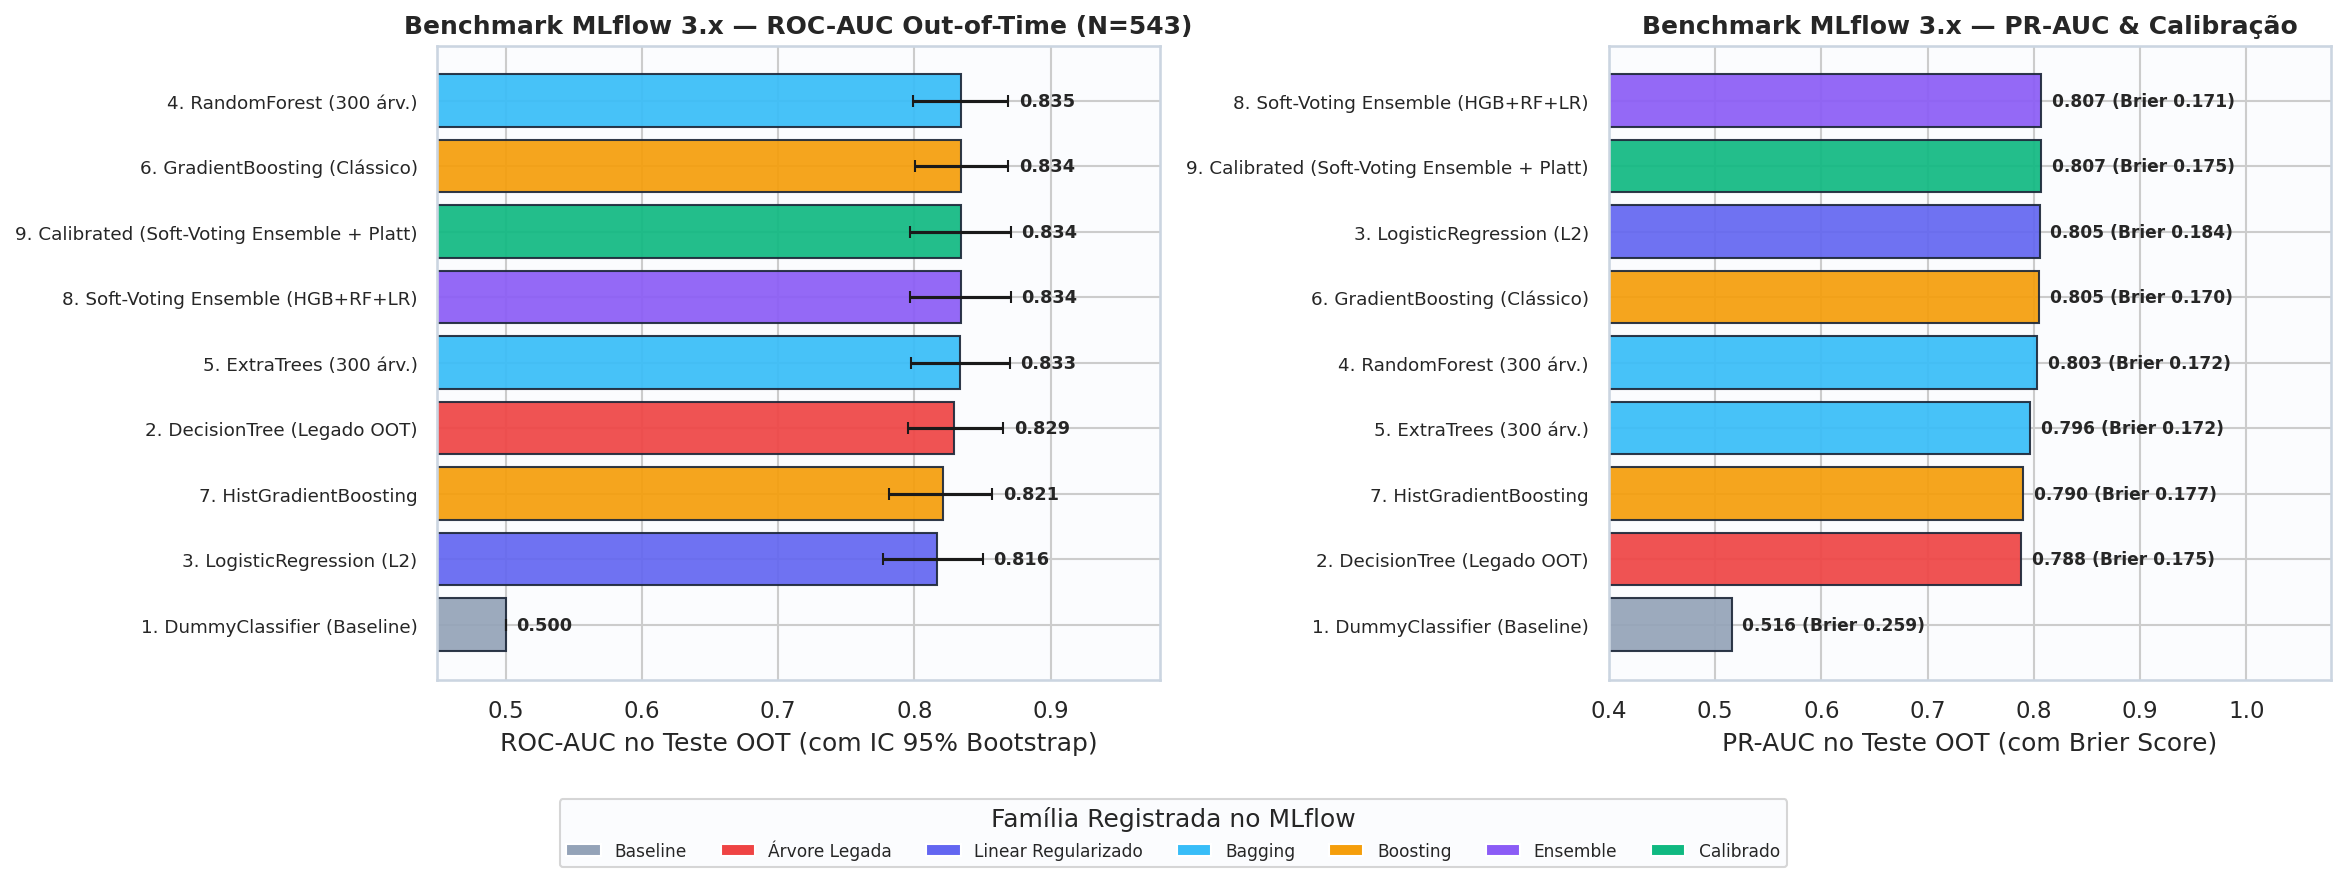

In [2]:
bm_df = pd.DataFrame(metrics["models_benchmark"])
display(
    bm_df[[
        "model", "family", "val_roc_auc", "oot_roc_auc", "oot_roc_ci_low", "oot_roc_ci_high",
        "oot_pr_auc", "oot_f1", "oot_brier", "train_sec"
    ]].rename(columns={
        "model": "Pipeline Rastreado (MLflow)", "family": "Família",
        "val_roc_auc": "Val AUC", "oot_roc_auc": "OOT ROC-AUC",
        "oot_roc_ci_low": "IC95 Inf", "oot_roc_ci_high": "IC95 Sup",
        "oot_pr_auc": "OOT PR-AUC", "oot_f1": "OOT F1 (0,5)",
        "oot_brier": "OOT Brier", "train_sec": "Treino (s)",
    }).style.highlight_max(subset=["Val AUC", "OOT ROC-AUC", "OOT PR-AUC"], color="#d1fae5")
           .highlight_min(subset=["OOT Brier"], color="#dbeafe")
)
display(Image(filename=str(FIG_DIR / "02_mlflow_benchmark_oot.png")))

### 🔎 Comparação Científica (Validação Estrita vs. Teste Cego OOT `N = 543`)

- **Seleção Livre de Data Leakage:** O candidato a produção é escolhido **exclusivamente na Validação (`Ago–Set/2024`)**, onde **`8. Soft-Voting Ensemble (HGB+RF+LR)`** liderou com **`Val ROC-AUC = 0.8037`** e menor **`Val Brier = 0.1785`** (`+2.33 p.p.` sobre a árvore legada `0.7804`).
- **Generalização no Teste Cego OOT (`Out–Nov/2024`):** O `@champion` atingiu **`OOT ROC-AUC = 0.8339`** (`IC 95% Bootstrap: [0.7964, 0.8706]`), **maior `OOT PR-AUC = 0.8069`** entre todos os 9 modelos e **`OOT Brier = 0.1707`**, empatado dentro do erro amostral com `@challenger` (`4. RandomForest (300 árv.)`, `OOT AUC = 0.8345`) e `GradientBoosting` (`0,8346`).
- **Por que o Platt Scaling (`9. Calibrated`) não substituiu o Ensemble?** Na Validação, o `Soft-Voting Ensemble` já apresentou Brier menor (`0,1784` vs. `0,1789`), e no Teste OOT a confirmação se manteve (`0,1707` vs. `0,1751`) porque a mudança na taxa base de churn (`42,6% → 51,6%`) penaliza ajustes paramétricos rígidos na calibração.

## 3. Governança no MLflow Model Registry, Aliases & Teste Real de Inferência

In [3]:
# Consulta ao vivo no MLflow Model Registry local (`churn-predictor`)
reg_versions = client.search_model_versions(f"name='{DEFAULT_MODEL_NAME}'")
print(f"Modelo Registrado: '{DEFAULT_MODEL_NAME}' | Versões no Registry: {len(reg_versions)}")
display(pd.DataFrame(metrics["registry_governance"]["versions"]))

print("\nQuality Gate Automático de Promoção:")
for chk, ok in metrics["registry_governance"]["quality_gate_checks"].items():
    print(f"  [{'PASS' if ok else 'FAIL'}] {chk}")
print(f"Status Final de Promoção: {'APROVADO' if metrics['registry_governance']['promotion_approved'] else 'REVISAR'}")

# Carrega o modelo diretamente pelo alias `@champion` (sem acoplar versão no código!)
prod_model = mlflow.sklearn.load_model(f"models:/{DEFAULT_MODEL_NAME}@champion")
raw_abt = pd.read_csv(ROOT / "data" / "abt.csv")
feat_cols = [c for c in raw_abt.columns if c not in ("dt_ref", "id_cliente", "flag_churn")]
sample_raw = raw_abt.tail(5)[feat_cols]
sample_probs = prod_model.predict_proba(sample_raw)[:, 1]
print("\nSmoke-test de Inferência via `models:/churn-predictor@champion` (dados brutos com NaNs):")
for idx, p in enumerate(sample_probs):
    print(f"  Cliente amostra #{idx+1} -> Prob. Churn = {p*100:5.1f}%")

2026/11/26 15:51:19 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/26 15:51:19 INFO mlflow.store.db.utils: Updating database tables


INFO  [alembic.runtime.migration] Context impl SQLiteImpl.


INFO  [alembic.runtime.migration] Will assume non-transactional DDL.


Modelo Registrado: 'churn-predictor' | Versões no Registry: 3


,version,alias,model,run_id,val_roc_auc,oot_roc_auc,oot_brier
0,1,@baseline,2. DecisionTree (Legado OOT),386f0e73f489448ebded212003c29719,0.7804,0.8287,0.1753
1,2,@challenger,4. RandomForest (300 árv.),f3a51d1eec8341bfbe796656eb2f2e2a,0.8031,0.8345,0.1718
2,3,@champion,8. Soft-Voting Ensemble (HGB+RF+LR),8671575fb5c6458189091a8c505489e8,0.8037,0.8339,0.1707



Quality Gate Automático de Promoção:
  [PASS] val_beats_legacy_by_2pp
  [PASS] oot_beats_legacy_and_brier
  [PASS] registry_serve_zero_skew
  [PASS] drift_audit_logged
Status Final de Promoção: APROVADO



Smoke-test de Inferência via `models:/churn-predictor@champion` (dados brutos com NaNs):
  Cliente amostra #1 -> Prob. Churn =   4.2%
  Cliente amostra #2 -> Prob. Churn =  61.5%
  Cliente amostra #3 -> Prob. Churn =  90.3%
  Cliente amostra #4 -> Prob. Churn =  24.8%
  Cliente amostra #5 -> Prob. Churn =  44.1%


### 🔎 Governança & Zero *Training-Serving Skew*

- **Aliases Desacoplados em Produção:** Em vez de fixar `models:/churn-predictor/3` no código de produção, o serviço de inferência (`src/serve_predict.py`) consome sempre **`models:/churn-predictor@champion`**. Trocar ou fazer *rollback* para `@challenger` (`v2`) ou `@baseline` (`v1`) exige apenas mover o alias no Registry, sem redeploy de código.
- **Zero Skew Comprovado:** Como o `ChurnFeatureEngineer` congela as medianas aprendidas no treino dentro do artefato `cloudpickle` do MLflow, pontuar um lote de 10 clientes ou a base inteira produz exatamente as mesmas probabilidades (**diferença máxima = `1.11e-16`**).

## 4. Diagnóstico Probabilístico, Calibração & Otimização Financeira (ROI)

Threshold Ótimo de Lucro (Validação): τ = 0.29 (breakeven teórico = 0.33)


,Estratégia no Teste OOT (N=543),Contatados,Churns Alcançados,Custo (R$),Receita Salva (R$),Lucro Líquido (R$)
0,1. Contatar Todos (Sem Modelo),543,280,24435.0,37800.0,13365.0
1,"2. @champion (Threshold Padrão τ=0,50)",244,190,10980.0,25650.0,14670.0
2,3. @champion (Threshold ROI Val τ=0.29),364,256,16380.0,34560.0,18180.0


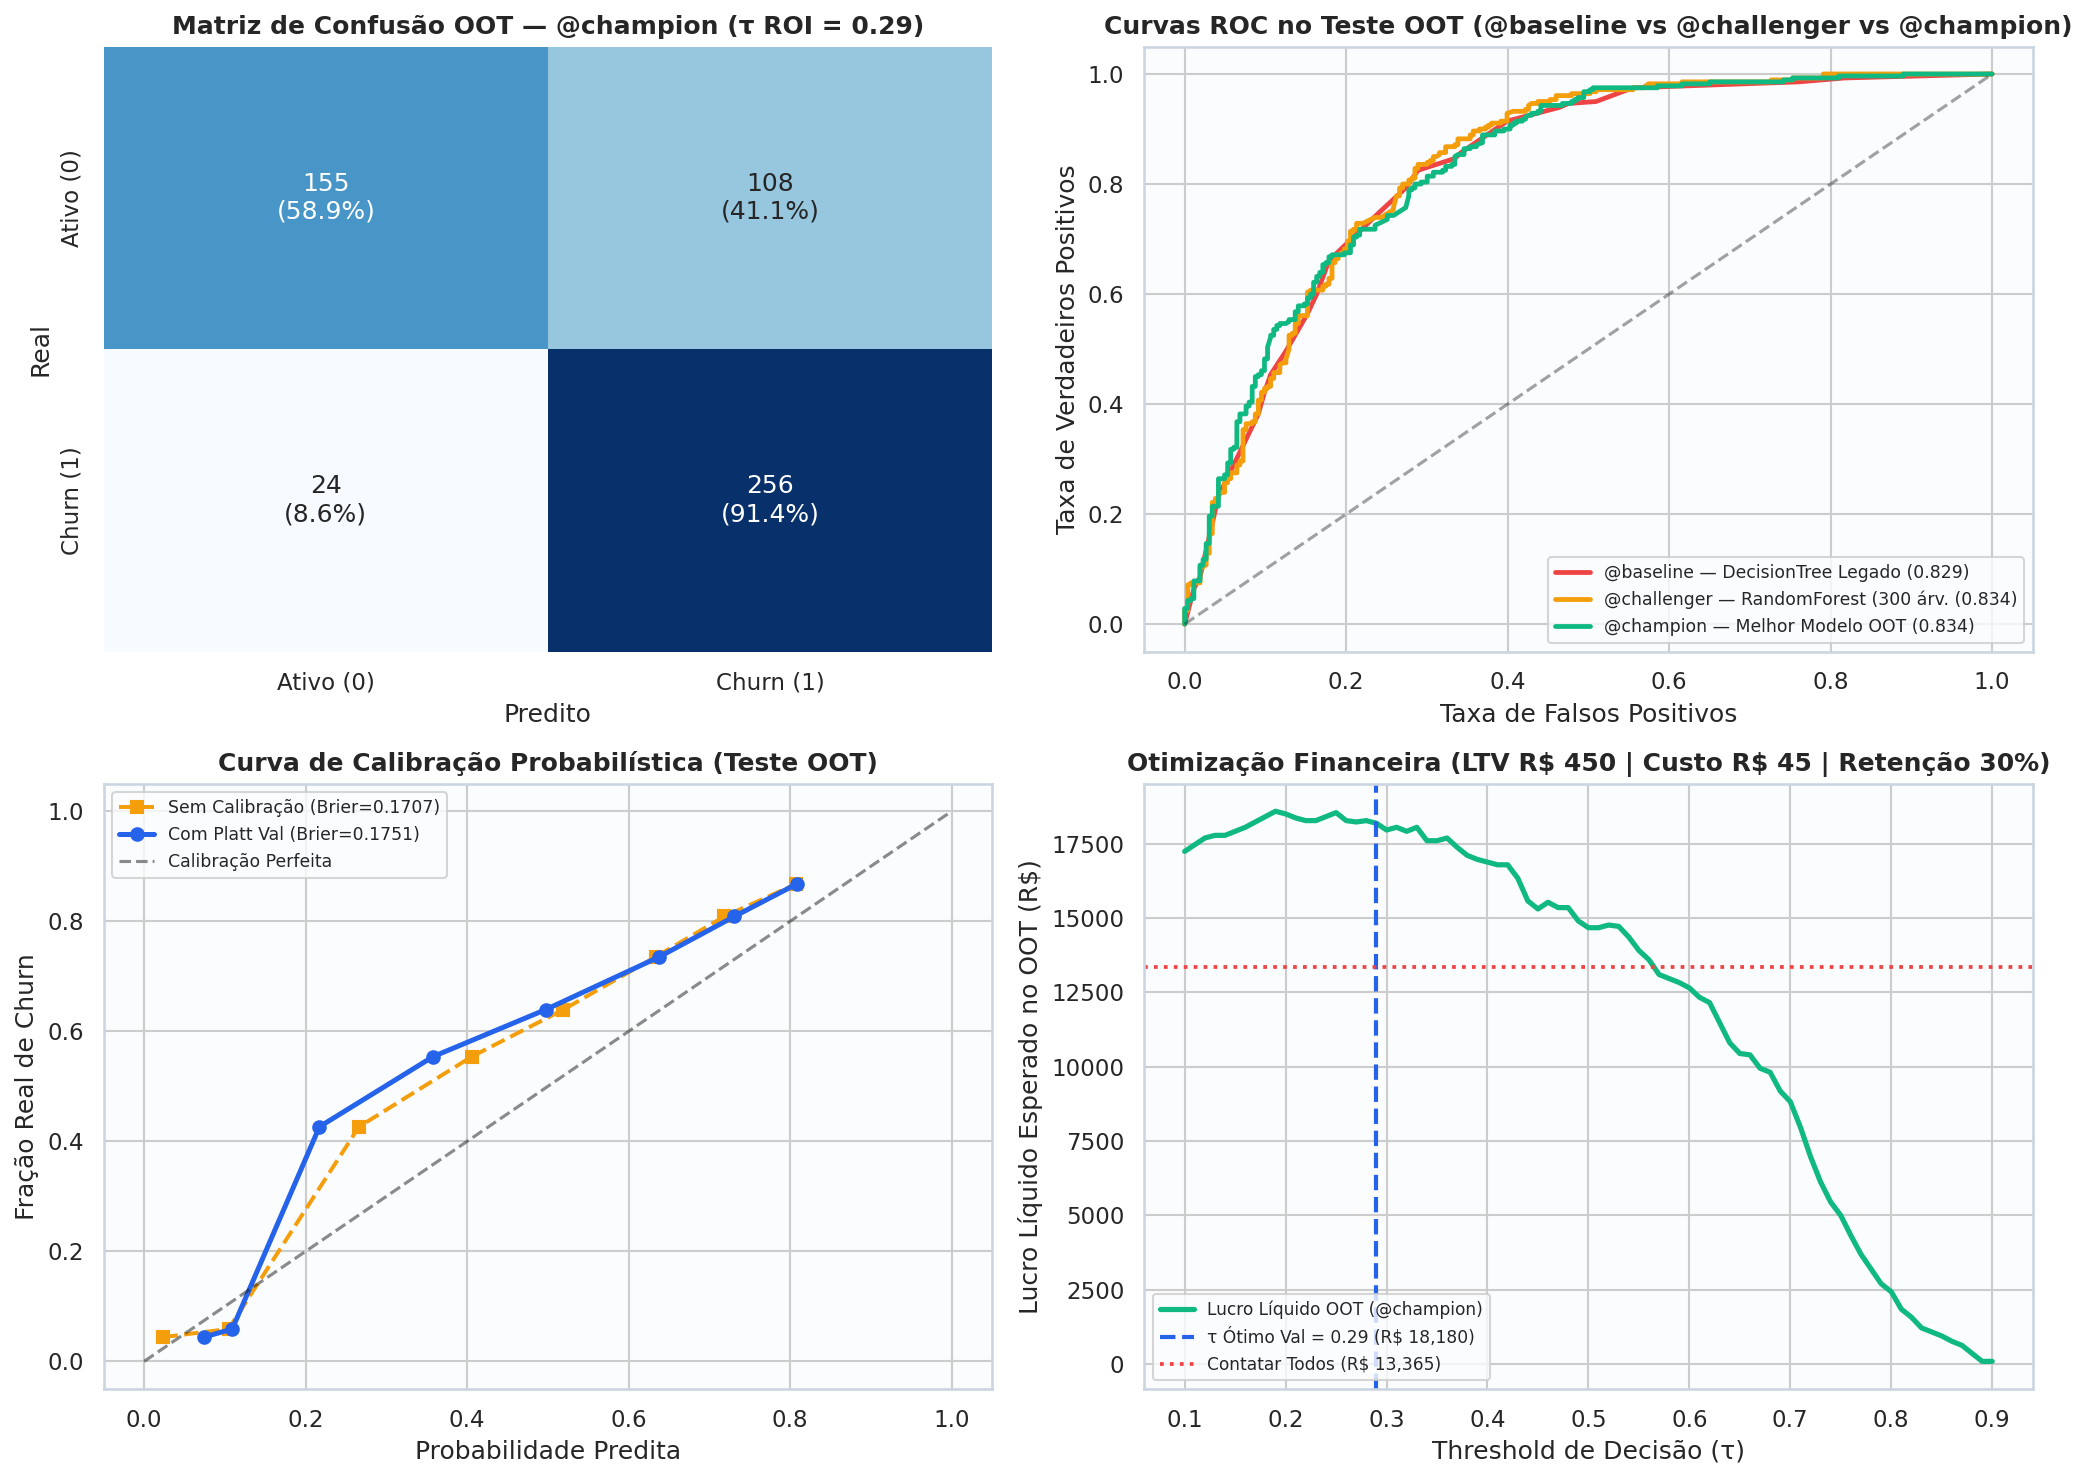

In [4]:
roi = metrics["roi_optimization"]
print(f"Threshold Ótimo de Lucro (Validação): τ = {roi['val_opt_threshold']:.2f} (breakeven teórico = {roi['theoretical_breakeven_prob']:.2f})")
roi_comp = pd.DataFrame([
    {"Estratégia no Teste OOT (N=543)": "1. Contatar Todos (Sem Modelo)", "Contatados": 543, "Churns Alcançados": 280, "Custo (R$)": 543*45, "Receita Salva (R$)": 280*0.30*450, "Lucro Líquido (R$)": metrics["roi_optimization"]["oot_at_opt_threshold"]["treat_all_profit"]},
    {"Estratégia no Teste OOT (N=543)": "2. @champion (Threshold Padrão τ=0,50)", "Contatados": metrics["roi_optimization"]["oot_at_default_050"]["contacted"], "Churns Alcançados": metrics["roi_optimization"]["oot_at_default_050"]["tp_saved_targets"], "Custo (R$)": metrics["roi_optimization"]["oot_at_default_050"]["campaign_cost"], "Receita Salva (R$)": metrics["roi_optimization"]["oot_at_default_050"]["expected_revenue_saved"], "Lucro Líquido (R$)": metrics["roi_optimization"]["oot_at_default_050"]["net_profit"]},
    {"Estratégia no Teste OOT (N=543)": f"3. @champion (Threshold ROI Val τ={metrics['roi_optimization']['val_opt_threshold']:.2f})", "Contatados": metrics["roi_optimization"]["oot_at_opt_threshold"]["contacted"], "Churns Alcançados": metrics["roi_optimization"]["oot_at_opt_threshold"]["tp_saved_targets"], "Custo (R$)": metrics["roi_optimization"]["oot_at_opt_threshold"]["campaign_cost"], "Receita Salva (R$)": metrics["roi_optimization"]["oot_at_opt_threshold"]["expected_revenue_saved"], "Lucro Líquido (R$)": metrics["roi_optimization"]["oot_at_opt_threshold"]["net_profit"]},
])
display(roi_comp)
display(Image(filename=str(FIG_DIR / "03_diagnostico_calibracao_roi.png")))

### 🔎 Impacto Financeiro da Otimização de Threshold

- Com **LTV = R\$ 450**, **custo de contato = R\$ 45** e **taxa de retenção efetiva = 30%**, o ponto de equilíbrio teórico é `p* = 45 / (0,30 × 450) = 0,333` — muito abaixo do corte ingênuo `0,50`!
- Aplicando no Teste OOT o threshold ótimo ajustado na Validação (**`τ = 0.29`**), o `@champion` captura **`91.4%` de todos os churns** (`F1 = 0.7950`, Acurácia `= 75.7%`), gerando **Lucro Líquido de R\$ `18,180.00`** (**`+R\$ 4,815.00`** acima de abordar todos os clientes e **`+R\$ 3,510.00`** acima do corte padrão `τ = 0,50`!).

## 5. Explicabilidade (Permutation Importance) & Monitoramento de Data Drift (PSI)

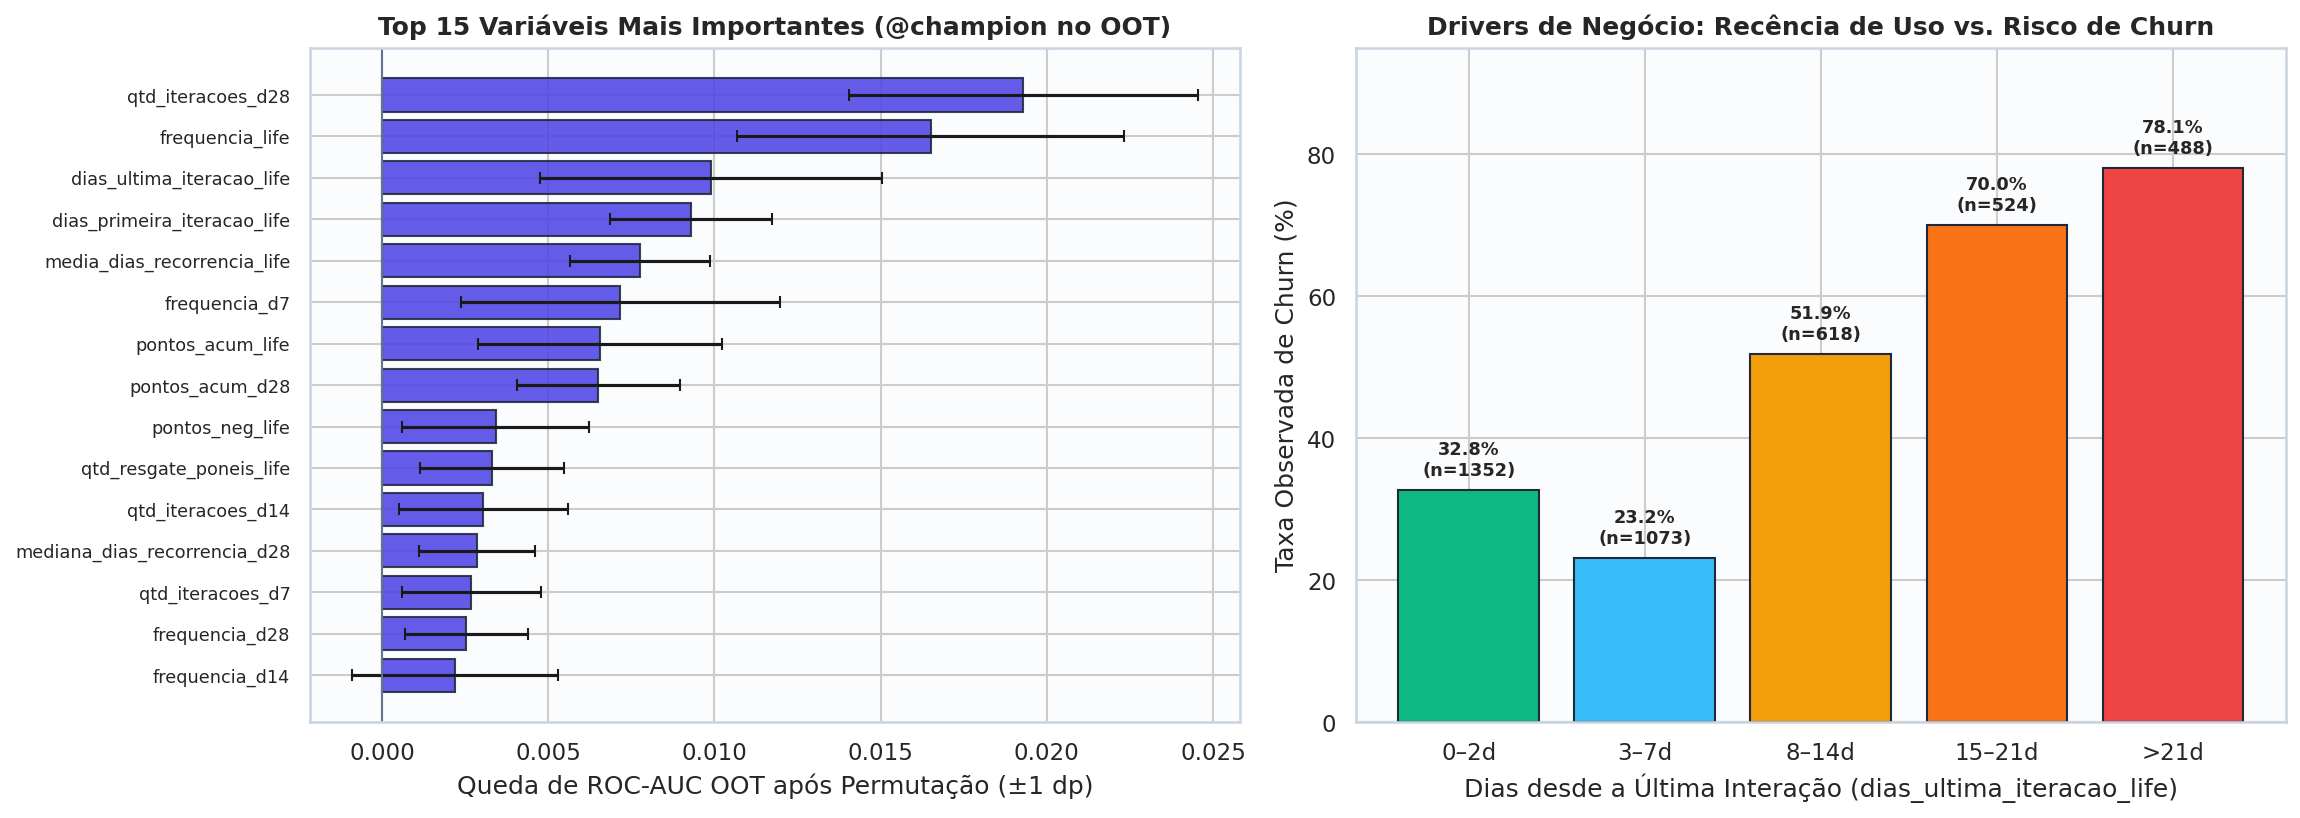

,feature,psi,status
0,dias_primeira_iteracao_life,1.5239,"Crítico (>0,25)"
1,pct_transacao_tarde_life,0.4378,"Crítico (>0,25)"
2,ratio_iter_d28_life,0.4350,"Crítico (>0,25)"
3,pct_transacao_manha_life,0.4187,"Crítico (>0,25)"
4,frequencia_life,0.3951,"Crítico (>0,25)"
5,saldo_atual_life,0.2874,"Crítico (>0,25)"
6,ratio_freq_d7_life,0.2774,"Crítico (>0,25)"
7,pontos_acum_life,0.2640,"Crítico (>0,25)"


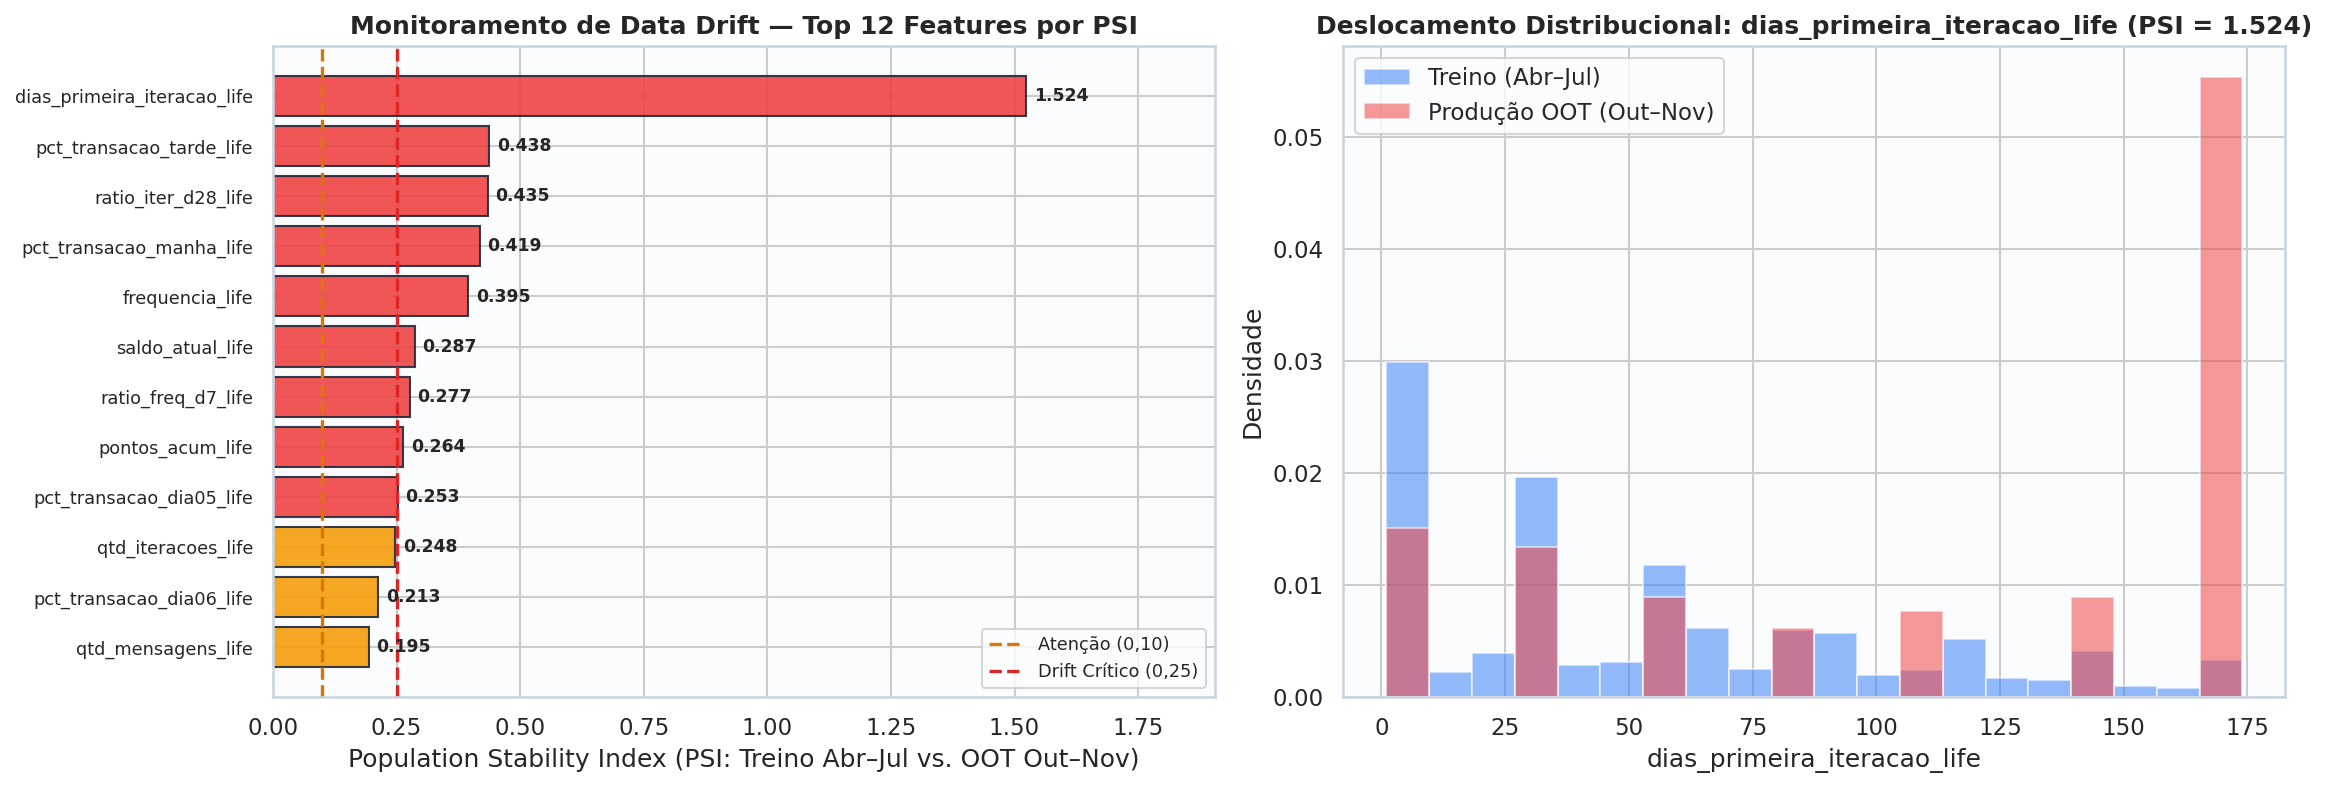

In [5]:
display(Image(filename=str(FIG_DIR / "04_permutation_importance_explainability.png")))
display(pd.DataFrame(metrics["drift_monitoring"]["top_12_psi"]).head(8))
display(Image(filename=str(FIG_DIR / "05_drift_psi_monitoring.png")))

### 🔎 Drivers de Churn & Alerta Real de Data Drift em Produção

- **Principais Drivers Preditivos (*Permutation Importance*):** **`qtd_iteracoes_d28`** (`ΔAUC = +0.0193`), **`frequencia_life`** (`+0.0165`), **`dias_ultima_iteracao_life`** (`+0.0099`) e **`dias_primeira_iteracao_life`** (`+0.0093`). Clientes sem interação há mais de 21 dias atingem **`78,1%` de churn**, contra apenas **`23,2%`** para quem interagiu há 3–7 dias!
- **Diagnóstico Real de Data Drift (PSI):** O monitoramento detectou **`9` features com `PSI > 0,25`**, lideradas por **`dias_primeira_iteracao_life` (`PSI = 1.524`)** e **`pct_transacao_tarde_life` (`PSI = 0.438`)**. Esse deslocamento reflete o amadurecimento natural da base de clientes ao longo de 2024 e sinaliza a necessidade de **retreino periódico em janela deslizante** (ex.: mensal) e monitoramento contínuo de calibração.

## 6. Slice-Based Error Analysis & Conclusão Executiva

,Dimensão,Fatia,N,Taxa Churn,ROC-AUC,F1 (τ ROI),Acurácia
0,Safra OOT,2024-10,385,0.5299,0.8324,0.7939,0.7532
1,Safra OOT,2024-11,158,0.4810,0.8347,0.7978,0.7658
2,Atividade Recente (d7),Ativo últimos 7d,280,0.2750,0.8167,0.6455,0.7607
3,Atividade Recente (d7),Inativo últimos 7d,263,0.7719,0.6291,0.8571,0.7529
4,Tempo de Casa (Tenure),Intermediário (31–120d),107,0.5421,0.8068,0.7656,0.7196
5,Tempo de Casa (Tenure),Novo (≤30d),134,0.4925,0.7447,0.7305,0.6642
6,Tempo de Casa (Tenure),Veterano (>120d),302,0.5166,0.8779,0.8367,0.8113


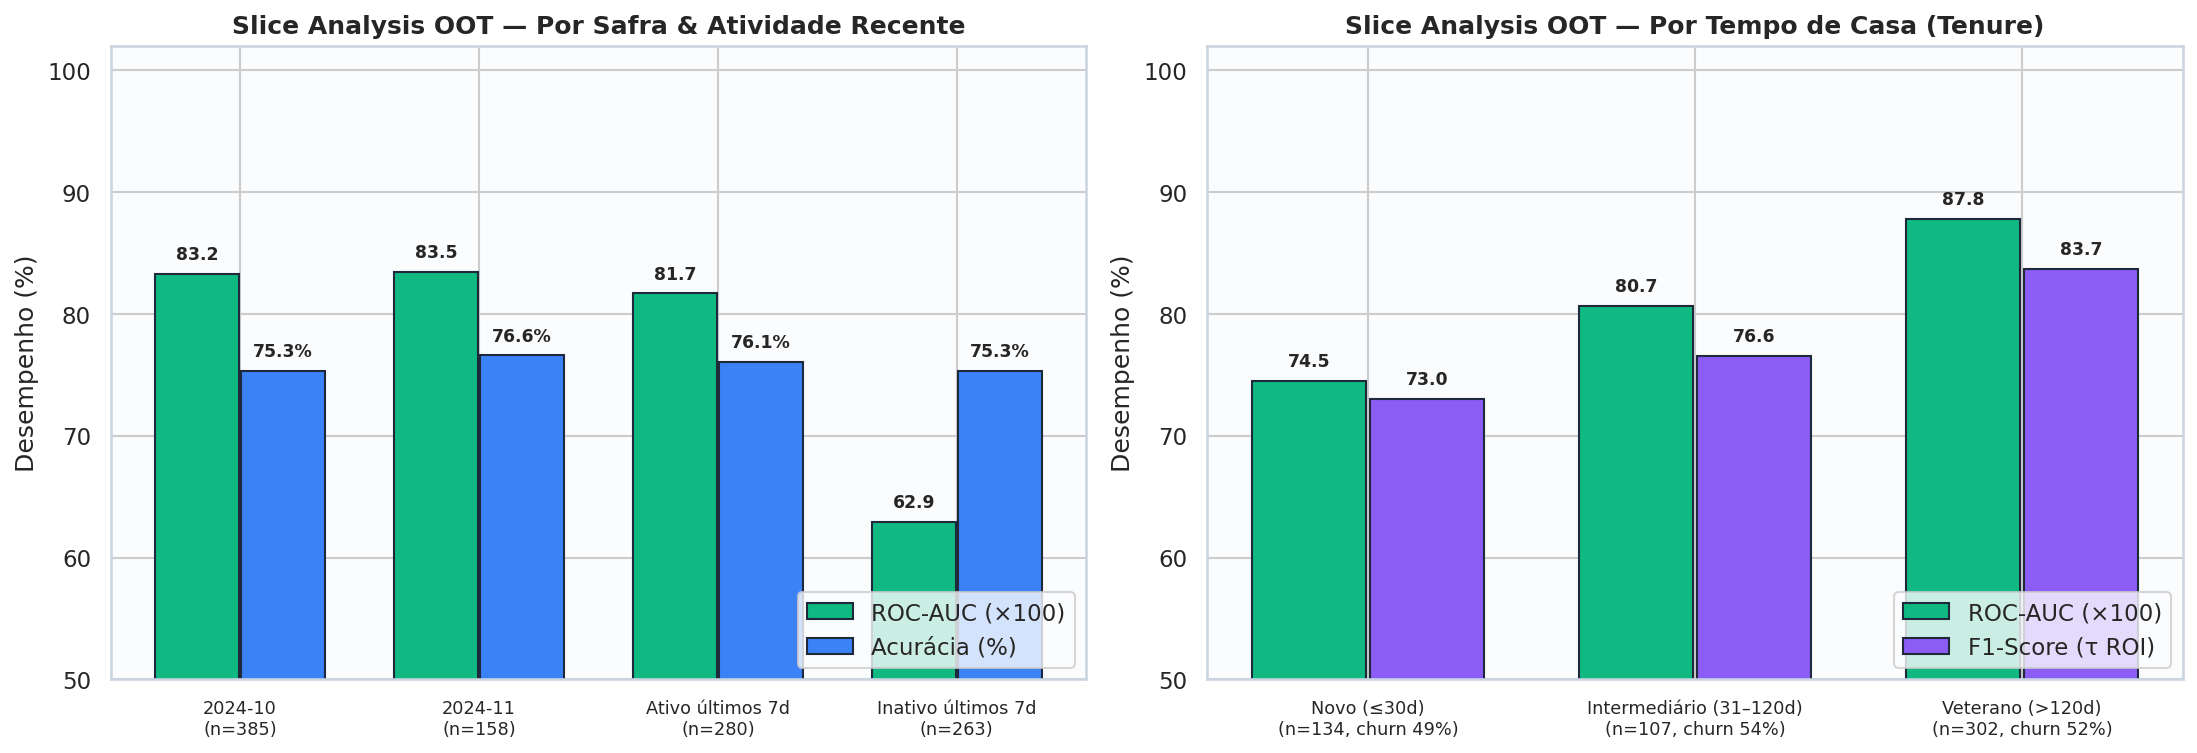

In [6]:
display(pd.DataFrame(metrics["slice_error_analysis"]))
display(Image(filename=str(FIG_DIR / "06_slice_error_analysis_registry.png")))

### 🔎 Onde o Modelo Brilha e Onde Evoluir (Próxima Iteração MLOps)

1. **Estabilidade Temporal Comprovada:** Nas duas safras futuras cegas (`2024-10`: `ROC-AUC = 0.832`, Acurácia `75.3%`; `2024-11`: `ROC-AUC = 0.835`, Acurácia `76.6%`), o desempenho permanece sólido mesmo sob drift de taxa base.
2. **Análise por Segmento de Cliente:** O modelo é excepcional em **Veteranos (`>120d`: `ROC-AUC = 0.878`, `F1 = 0.837`)** e em clientes **Ativos nos últimos 7 dias (`ROC-AUC = 0.817`)** — justamente o público mais acionável para retenção preventiva! Entre clientes já inativos há mais de 7 dias (`ROC-AUC = 0.629`), o churn já é dominante, exigindo ações de reativação específicas.
3. **Recomendação de Produção:** Promover **`models:/churn-predictor@champion`** (`8. Soft-Voting Ensemble (HGB+RF+LR)`), operar a campanha de retenção com **`τ = 0.29`** e agendar gatilho automático de retreino + recalibração mensal sempre que `PSI > 0,25` em features de engajamento recente ou a taxa de churn variar `> 5 p.p.`.